# 2021 — Masked Autoencoders (MAE)

**Paper:** Kaiming He, Xinlei Chen, Saining Xie, Yanghao Li, Piotr Dollár & Ross Girshick, *"Masked Autoencoders Are Scalable Vision Learners"* (2021, CVPR 2022). Related: BEiT (Bao et al., 2021), SimMIM (Xie et al., 2021).

BERT (notebook 42) learned language by **masking words and predicting them**. For images, this did not work well at first. MAE found the two changes that made it work:

1. **Mask a lot.** Neighbouring pixels are highly redundant, so masking 15% (as in BERT) is too easy: a model can interpolate. MAE masks **75%** of the image patches, forcing it to understand objects to fill them in.
2. **Asymmetric encoder–decoder.** The ViT encoder (notebook 49) sees **only the visible 25% of patches**, with no mask tokens at all, so pre-training is ~3× cheaper. A small, separate decoder takes the encoded visible patches plus mask tokens and reconstructs the pixels; it is thrown away after pre-training.

The loss is the mean squared error on the **masked** patches only. After pre-training on unlabelled images, the encoder is a strong feature extractor. MAE pre-trained ViT-Huge reached 87.8% on ImageNet-1K with no extra data, and masked modelling is now standard in vision (and in video and audio).

![Diagram: Masked autoencoders (He et al., 2021)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/53_2021_masked_autoencoder.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors(size=16)]
P = 4; NP = (16 // P) ** 2                                                    # 4×4 patches → 16 patches per image
def patchify(x): return x.unfold(2, P, P).unfold(3, P, P).reshape(len(x), NP, P * P)
def unpatchify(p): return p.view(len(p), 4, 4, P, P).permute(0, 1, 3, 2, 4).reshape(len(p), 1, 16, 16)

In [3]:
class MAE(nn.Module):
    def __init__(self, d=128, depth=4, dec_d=64, dec_depth=2):
        super().__init__()
        self.embed = nn.Linear(P * P, d); self.pos = nn.Parameter(torch.randn(NP, d) * 0.02)
        L = lambda dd: nn.TransformerEncoderLayer(dd, 4, 4 * dd, 0.0, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(L(d), depth); self.norm = nn.LayerNorm(d)
        self.dec_in = nn.Linear(d, dec_d); self.mask_token = nn.Parameter(torch.zeros(dec_d)); self.dec_pos = nn.Parameter(torch.randn(NP, dec_d) * 0.02)
        self.decoder = nn.TransformerEncoder(L(dec_d), dec_depth); self.pred = nn.Linear(dec_d, P * P)
    def encode(self, patches, keep_idx=None):
        h = self.embed(patches) + self.pos
        if keep_idx is not None: h = h.gather(1, keep_idx[..., None].expand(-1, -1, h.shape[-1]))   # drop masked patches entirely
        return self.norm(self.encoder(h))
    def forward(self, x, mask_ratio):
        p = patchify(x); B = len(p); n_keep = max(1, int(round(NP * (1 - mask_ratio))))
        order = torch.rand(B, NP, device=x.device).argsort(1); keep, masked = order[:, :n_keep], order[:, n_keep:]
        z = self.dec_in(self.encode(p, keep))
        full = self.mask_token.expand(B, NP, -1).clone()
        full.scatter_(1, keep[..., None].expand(-1, -1, z.shape[-1]), z)                         # put visible tokens back in place
        rec = self.pred(self.decoder(full + self.dec_pos))
        target = (p - p.mean(-1, keepdim=True)) / (p.std(-1, keepdim=True) + 1e-6)              # per-patch normalised pixels (as in MAE)
        m = torch.zeros(B, NP, device=x.device).scatter_(1, masked, 1.0)
        loss = (((rec - target) ** 2).mean(-1) * m).sum() / m.sum()
        return loss, rec, m
    def features(self, x):
        with torch.no_grad(): return self.encode(patchify(x)).mean(1)                           # all patches visible at test time

def pretrain(mask_ratio, steps=4000, seed=0):
    seed_everything(seed); m = MAE().to(device); opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, 1e-3, total_steps=steps, pct_start=0.1)
    for s in range(steps):
        x = Xtr[torch.randint(0, len(Xtr), (128,), device=device)]
        x = torch.roll(x, shifts=tuple(np.random.randint(-1, 2, 2)), dims=(2, 3))             # light augmentation: ±1px shift
        loss, _, _ = m(x, mask_ratio); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return m.eval()

def linear_probe(feat_fn, n_labels=None, epochs=300):
    """Logistic regression on frozen features, optionally with only n_labels labelled training images."""
    Ftr, Fte = feat_fn(Xtr), feat_fn(Xte); idx = torch.arange(len(Ftr), device=device) if n_labels is None else torch.randperm(len(Ftr), generator=torch.Generator().manual_seed(0))[:n_labels].to(device)
    mu, sd = Ftr[idx].mean(0), Ftr[idx].std(0) + 1e-6
    seed_everything(0); clf = nn.Linear(Ftr.shape[1], 10).to(device); opt = torch.optim.Adam(clf.parameters(), lr=1e-2, weight_decay=1e-3)
    for _ in range(epochs):
        loss = F.cross_entropy(clf((Ftr[idx] - mu) / sd), ytr[idx]); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad(): return (clf((Fte - mu) / sd).argmax(1) == yte).float().mean().item()

/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_3759/3708910691.py:6: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(L(d), depth); self.norm = nn.LayerNorm(d)
/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_3759/3708910691.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.decoder = nn.TransformerEncoder(L(dec_d), dec_depth); self.pred = nn.Linear(dec_d, P * P)


pre-trained with 75% masking in 60s (no labels used)


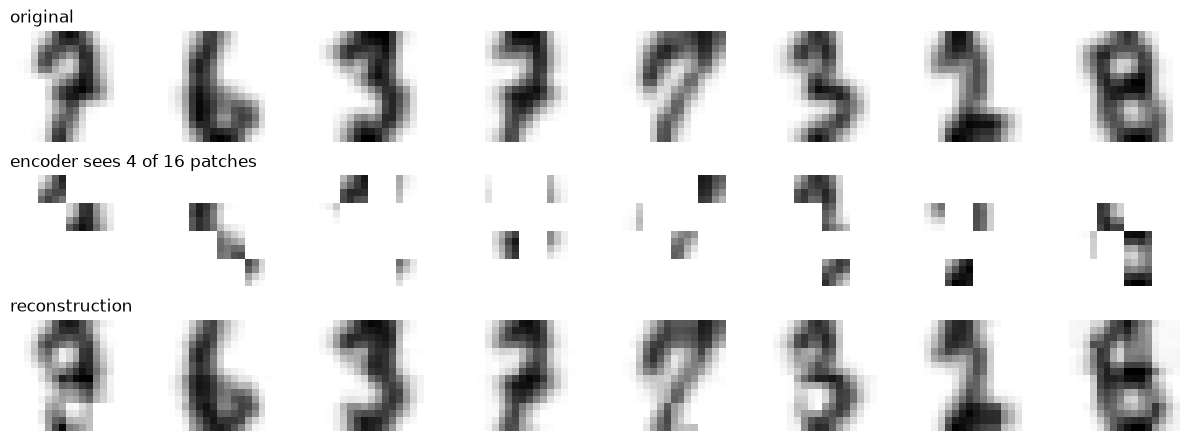

In [4]:
t0 = time.time(); mae = pretrain(0.75); print(f"pre-trained with 75% masking in {time.time() - t0:.0f}s (no labels used)")
with torch.no_grad():
    loss, rec, m = mae(Xte[:8], 0.75)
p = patchify(Xte[:8]); mu, sd = p.mean(-1, keepdim=True), p.std(-1, keepdim=True) + 1e-6
recon = unpatchify(torch.where(m[..., None] > 0, rec * sd + mu, p)); masked_img = unpatchify(p * (1 - m[..., None]))
fig, axes = plt.subplots(3, 8, figsize=(12, 4.5))
for i in range(8):
    for r, img in enumerate([Xte[i], masked_img[i], recon[i]]): axes[r, i].imshow(img[0].cpu(), cmap="gray_r", vmin=0, vmax=1); axes[r, i].axis("off")
axes[0, 0].set_title("original", loc="left"); axes[1, 0].set_title("encoder sees 4 of 16 patches", loc="left"); axes[2, 0].set_title("reconstruction", loc="left")
plt.tight_layout(); plt.show()

## How good are the learned features?
Freeze the encoder and train only a **linear classifier** on its mean-pooled output (a "linear probe"), with all labels and with only 50 labels (5 per class). Compared with the same encoder left at random initialisation, and with raw pixels.

In [5]:
rand_enc = MAE().to(device).eval()
rows = [("raw pixels", lambda X: X.flatten(1)), ("random-init ViT encoder", rand_enc.features), ("MAE-pretrained encoder (75%)", mae.features)]
for name, f in rows:
    print(f"{name:30s} linear probe: all {len(Xtr)} labels {linear_probe(f):.3f} | 50 labels {linear_probe(f, 50):.3f}")

/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_3759/3708910691.py:6: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(L(d), depth); self.norm = nn.LayerNorm(d)
/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_3759/3708910691.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.decoder = nn.TransformerEncoder(L(dec_d), dec_depth); self.pred = nn.Linear(dec_d, P * P)


raw pixels                     linear probe: all 1437 labels 0.956 | 50 labels 0.806


random-init ViT encoder        linear probe: all 1437 labels 0.931 | 50 labels 0.522


MAE-pretrained encoder (75%)   linear probe: all 1437 labels 0.972 | 50 labels 0.844


## How much should we mask?
Pre-train with different mask ratios and compare linear-probe accuracy with 50 labels (mean of 2 pre-training seeds).

/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_3759/3708910691.py:6: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(L(d), depth); self.norm = nn.LayerNorm(d)
/var/folders/wc/dmtxvwwd4yd6x5qrr6981_v40000gn/T/ipykernel_3759/3708910691.py:8: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.decoder = nn.TransformerEncoder(L(dec_d), dec_depth); self.pred = nn.Linear(dec_d, P * P)


mask ratio 0.25: linear probe (50 labels) 0.822


mask ratio 0.50: linear probe (50 labels) 0.854


mask ratio 0.75: linear probe (50 labels) 0.853


mask ratio 0.90: linear probe (50 labels) 0.819


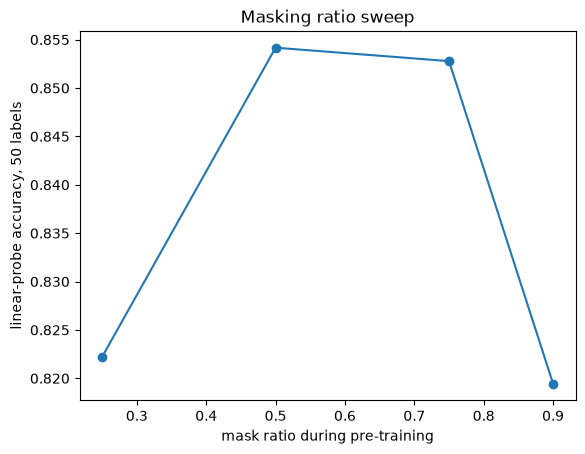

In [6]:
ratios, accs = [0.25, 0.5, 0.75, 0.9], []
for r in ratios:
    a = np.mean([linear_probe(pretrain(r, seed=s).features, 50) for s in range(2)]); accs.append(a)
    print(f"mask ratio {r:.2f}: linear probe (50 labels) {a:.3f}")
plt.plot(ratios, accs, marker="o"); plt.xlabel("mask ratio during pre-training"); plt.ylabel("linear-probe accuracy, 50 labels"); plt.title("Masking ratio sweep"); plt.show()

## Takeaways
- **Hide most of the image and predict it back.** The task is hard enough to require knowledge of shapes, and needs no labels. The pre-trained encoder's features separate the classes far better than random features, even with only 5 labels per class. On 8×8 digits, raw pixels are already a strong linear baseline, so MAE's margin over them is small here; on natural images the gap is large.
- **Efficiency comes from the asymmetry:** the encoder only processes visible patches (4 of 16 here, 49 of 196 in the paper).
- On this tiny dataset the curve is flat between 50% and 75% masking: 16 patches are very few, and how much redundancy there is to remove depends on the images. The paper's sweep on ImageNet peaked at 75% for both fine-tuning and linear probing.
- Masked prediction is now a common objective across modalities: masked image modelling, masked audio (AudioMAE), video (VideoMAE), and the masked-token diffusion language models of 2025 (notebook 73).